# Ensamble soft-voting del escenario extendido

Reutiliza los modelos ya entrenados por `01_modelos_extendido.ipynb` (no los re-entrena) y combina sus probabilidades. Los pesos se seleccionan **solo en validación**; el test se evalúa una vez.

**Por qué soft-voting:** RF, XGBoost y LightGBM cometen errores distintos. Promediar probabilidades suele reducir varianza y mejorar marginalmente la accuracy. El modelo ordinal se excluye porque su accuracy es claramente menor y su probabilidad no está calibrada de la misma forma.

Requiere: `models/random_forest_ext.joblib`, `models/xgboost_ext.joblib`, `models/lightgbm_ext.joblib`.

In [2]:
import sys
sys.path.append('../..')

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import evaluar_modelo_ordinal, metricas_a_fila
from src.preprocessing_features import FEATURES_EXT_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    MODELS_DIR,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [3]:
df = preparar_dataset_features(
    cargar_dataset(FEATURES_EXT_PATH),
    descartar_baseline=False,
)
X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

rutas = {
    'random_forest': MODELS_DIR / 'random_forest_ext.joblib',
    'xgboost': MODELS_DIR / 'xgboost_ext.joblib',
    'lightgbm': MODELS_DIR / 'lightgbm_ext.joblib',
}
faltantes = [str(ruta) for ruta in rutas.values() if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(
        'Faltan modelos extendidos. Ejecuta 01_modelos_extendido.ipynb.\n' + '\n'.join(faltantes)
    )

modelos = {nombre: joblib.load(ruta) for nombre, ruta in rutas.items()}
print('Modelos cargados:', list(modelos))

Train: (43131, 151) Val: (9243, 151) Test: (9243, 151)
Modelos cargados: ['random_forest', 'xgboost', 'lightgbm']


In [4]:
def probabilidades_alineadas(modelo, X):
    proba = modelo.predict_proba(X)
    clases_modelo = list(modelo.named_steps['modelo'].classes_)
    if all(isinstance(c, (int, np.integer)) for c in clases_modelo):
        clases_modelo = [CLASES[int(c)] for c in clases_modelo]
    orden = [clases_modelo.index(clase) for clase in CLASES]
    return proba[:, orden]

proba_val = {nombre: probabilidades_alineadas(modelo, X_val) for nombre, modelo in modelos.items()}
proba_test = {nombre: probabilidades_alineadas(modelo, X_test) for nombre, modelo in modelos.items()}

for nombre in modelos:
    pred = np.asarray(CLASES)[proba_val[nombre].argmax(axis=1)]
    met = evaluar_modelo_ordinal(y_val, pred)
    print(nombre, {k: round(v, 4) for k, v in met.items() if k != 'matriz_confusion'})

random_forest {'accuracy': 0.7147, 'balanced_accuracy': 0.7143, 'f1_macro': 0.7128, 'f1_weighted': 0.7131, 'accuracy_adjacent': 0.9719, 'mae_ordinal': 0.3186, 'qwk': 0.8436}
xgboost {'accuracy': 0.7229, 'balanced_accuracy': 0.7226, 'f1_macro': 0.7224, 'f1_weighted': 0.7227, 'accuracy_adjacent': 0.9787, 'mae_ordinal': 0.3008, 'qwk': 0.8591}
lightgbm {'accuracy': 0.7308, 'balanced_accuracy': 0.7305, 'f1_macro': 0.7303, 'f1_weighted': 0.7305, 'accuracy_adjacent': 0.9791, 'mae_ordinal': 0.2923, 'qwk': 0.8631}


In [5]:
from sklearn.metrics import f1_score

nombres = ['random_forest', 'xgboost', 'lightgbm']
mejor = None

# Pesos en pasos de 0.1 que suman 1.0.
for i in range(11):
    for j in range(11 - i):
        k = 10 - i - j
        pesos = np.array([i, j, k], dtype=float) / 10.0
        proba = sum(
            peso * proba_val[nombre] for peso, nombre in zip(pesos, nombres)
        )
        pred = np.asarray(CLASES)[proba.argmax(axis=1)]
        f1 = f1_score(y_val, pred, average='macro')
        if mejor is None or f1 > mejor['f1_macro']:
            mejor = {
                'pesos': dict(zip(nombres, pesos.tolist())),
                'f1_macro': float(f1),
                'pred': pred,
            }

print('Mejores pesos (validación):', mejor['pesos'])
print('F1-Macro validación:', round(mejor['f1_macro'], 4))
print('Validación:', {k: round(v, 4) for k, v in evaluar_modelo_ordinal(y_val, mejor['pred']).items() if k != 'matriz_confusion'})

Mejores pesos (validación): {'random_forest': 0.1, 'xgboost': 0.4, 'lightgbm': 0.5}
F1-Macro validación: 0.7334
Validación: {'accuracy': 0.734, 'balanced_accuracy': 0.7336, 'f1_macro': 0.7334, 'f1_weighted': 0.7337, 'accuracy_adjacent': 0.9798, 'mae_ordinal': 0.2884, 'qwk': 0.8653}


Test: {'accuracy': 0.7303, 'balanced_accuracy': 0.73, 'f1_macro': 0.7295, 'f1_weighted': 0.7297, 'accuracy_adjacent': 0.9788, 'mae_ordinal': 0.2946, 'qwk': 0.8599}


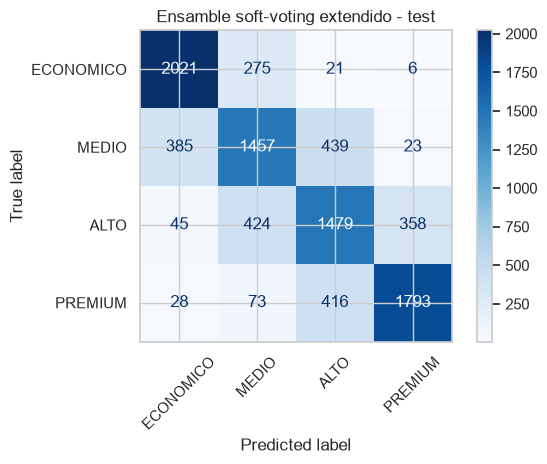

Resultados guardados en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports


In [6]:
pesos = mejor['pesos']
proba_ensamble = sum(
    pesos[nombre] * proba_test[nombre] for nombre in nombres
)
pred_test = np.asarray(CLASES)[proba_ensamble.argmax(axis=1)]
met_test = evaluar_modelo_ordinal(y_test, pred_test)
print('Test:', {k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

ConfusionMatrixDisplay(
    met_test['matriz_confusion'], display_labels=CLASES
).plot(cmap='Blues', values_format='d')
plt.title('Ensamble soft-voting extendido - test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'ensemble_ext_matriz_confusion.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

pd.DataFrame(
    [
        metricas_a_fila(
            'ensemble_ext',
            met_test,
            escenario='extendido_ensemble',
            pesos=json.dumps(pesos),
        )
    ]
).to_csv(REPORTS_DIR / 'ensemble_ext_metricas.csv', index=False)

with open(REPORTS_DIR / 'ensemble_ext_pesos.json', 'w', encoding='utf-8') as archivo:
    json.dump(
        {
            'pesos': pesos,
            'f1_macro_val': float(mejor['f1_macro']),
            'accuracy_test': float(met_test['accuracy']),
            'f1_macro_test': float(met_test['f1_macro']),
            'accuracy_adjacent_test': float(met_test['accuracy_adjacent']),
        },
        archivo,
        indent=2,
        ensure_ascii=False,
    )
print('Resultados guardados en:', REPORTS_DIR)

,modelo,accuracy,f1_macro,accuracy_adjacent,qwk
3,ensemble_ext,0.730282,0.729466,0.978795,0.859895
2,lightgbm,0.729741,0.728812,0.978362,0.859333
1,xgboost,0.724224,0.723944,0.978795,0.856802
0,random_forest,0.711674,0.710139,0.971330,0.839313


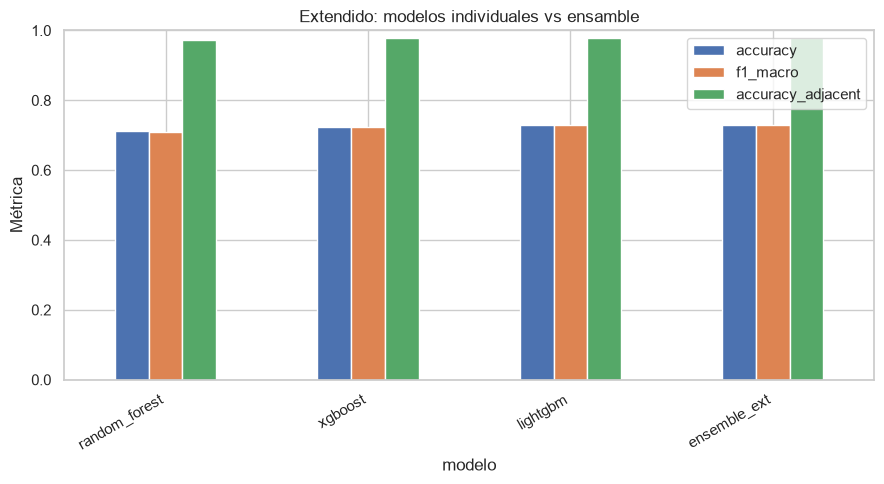

In [7]:
filas = []
for nombre in nombres:
    ruta = REPORTS_DIR / f'{nombre}_ext_metricas.csv'
    if ruta.exists():
        fila = pd.read_csv(ruta).iloc[0].to_dict()
        fila['modelo'] = nombre
        filas.append(fila)

ruta_ensamble = REPORTS_DIR / 'ensemble_ext_metricas.csv'
if ruta_ensamble.exists():
    filas.append(pd.read_csv(ruta_ensamble).iloc[0].to_dict())

comparacion = pd.DataFrame(filas)
columnas = ['modelo', 'accuracy', 'f1_macro', 'accuracy_adjacent', 'qwk']
columnas = [c for c in columnas if c in comparacion.columns]
display(comparacion[columnas].sort_values('f1_macro', ascending=False))

comparacion.set_index('modelo')[['accuracy', 'f1_macro', 'accuracy_adjacent']].plot(
    kind='bar', figsize=(9, 5)
)
plt.title('Extendido: modelos individuales vs ensamble')
plt.ylabel('Métrica')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'ensemble_ext_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Lectura de resultados

- Si el ensamble no supera al mejor modelo individual (probablemente LightGBM), se documenta y se conserva el individual. El ensamble no debe elegirse por complejidad, sino por ganancia real en validación.
- Los pesos se optimizaron en validación; el test no participó. Aun así, una ganancia < 0.005 está dentro del ruido y no justifica el ensamble en producción.
- `ensemble_ext_metricas.csv` se incorpora automáticamente a la comparación de escenarios si existe.